# 1. Understand the existing experiments

**Question:** How accurately can YOLO locate tobacco plants, and what does this tell us about weed targeting?

This notebook reproduces tables and graphs from the small artifacts already in the repository. It needs **no dataset, trained weights, GPU, or network access after setup**. Install `notebooks/requirements-analysis.txt`, select that Python kernel, then use **Restart Kernel and Run All**.

The method detects tobacco (the crop), thresholds green vegetation, removes crop boxes, and finds centroids of remaining regions. Those regions are **weed candidates**: green pixels alone do not establish that something is a weed.

Read the notebooks in order: this results walkthrough, detector reproduction, then mask generation and independent evaluation. The remaining three default to explanatory mode and require external inputs to run new experiments.


In [ ]:
from pathlib import Path
import sys
import os
import json
import tempfile

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'notebooks').is_dir() and (p / 'experiments/splits/items.csv').is_file()), None)
if ROOT is None:
    raise RuntimeError('Start Jupyter from the repository root or a subdirectory.')
if str(ROOT / 'notebooks') not in sys.path:
    sys.path.insert(0, str(ROOT / 'notebooks'))
from reproduction import frozen_assignments, check_detector_results
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'tobacco-notebook-mpl'))
os.environ.setdefault('YOLO_CONFIG_DIR', str(ROOT / 'experiments/.ultralytics'))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
RESULTS = ROOT / 'experiments/results'


## What evidence do we have?

The accompanying manuscript (`article.tex`) remains in the original article repository; it is not required to run these notebooks. The most direct sources for the detector results are the saved CSVs and JSON metadata, rather than older handoff instructions. Raw images and trained weights were transferred separately and are absent from this checkout. Manual weed masks and centers were not available in the recorded experiment.

The recorded software versions below describe the original Windows machine; they are provenance, not a promise that the same environment can be installed unchanged on another operating system.


In [2]:
summary = json.loads((ROOT / 'experiments/splits/summary.json').read_text())
environment = json.loads((RESULTS / 'environment/metadata.json').read_text())
settings = json.loads((RESULTS / 'yolo/run_metadata.json').read_text())
assignments = frozen_assignments(ROOT)
assert summary['images'] == 110 and summary['boxes'] == 4436
assert {k: len(v) for k, v in assignments.items()} == {'train': 78, 'val': 16, 'test': 16}
display(pd.DataFrame({'split': list(assignments), 'images': [len(v) for v in assignments.values()]}))
display(pd.Series({'images': summary['images'], 'tobacco boxes': summary['boxes'],
                  'class 0': summary['class_name'], 'split seed': summary['seed']}))
print(json.dumps(environment, indent=2))
print(json.dumps(settings, indent=2))


,split,images
0,train,78
1,val,16
2,test,16


images                110
tobacco boxes        4436
class 0           tobacco
split seed       20260627
dtype: object

{
  "platform": "Windows-11-10.0.26100-SP0",
  "system": "Windows",
  "release": "11",
  "machine": "AMD64",
  "processor": "AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD",
  "python_executable": "C:\\Users\\natsusa_aki\\academic\\academic-robot\\tabacco_article\\venv\\Scripts\\python.exe",
  "python_version": "3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]",
  "torch": {
    "available": true,
    "version": "2.12.1+cu132",
    "cuda_available": true,
    "torch_cuda": "13.2",
    "device_count": 1,
    "device_name": "NVIDIA GeForce RTX 5070 Ti"
  },
  "ultralytics_version": "8.4.81",
  "opencv_version": "4.13.0",
  "numpy_version": "2.5.0"
}
{
  "dataset": "data\\tobacco_yolo",
  "splits": "experiments\\splits",
  "models": [
    "yolov8n.pt",
    "yolov8m.pt",
    "yolov8x.pt"
  ],
  "epochs": 50,
  "imgsz": 1024,
  "batch": 14,
  "device": "0",
  "model_status": {
    "yolov8n": "ok",
    "yolov8m": "ok",
    "yolov8x": "ok"
  }
}


## Recreate the held-out test comparison

Training adjusts model parameters. Validation helps choose a checkpoint. The test split measures the selected checkpoint on held-out images.

- **Precision:** how often predicted tobacco detections are correct.
- **Recall:** how many annotated tobacco plants are found.
- **mAP@0.5:** average precision at an intersection-over-union matching threshold of 0.5.
- **mAP@0.5:0.95:** average precision across stricter overlap thresholds; this is more sensitive to box localization.

We explicitly select `test_...` columns. Unprefixed `metrics/...` columns come from the final training-log row and are not the article's test results. Inference time is the saved framework inference component per image, excluding preprocessing and postprocessing; it is not complete robot latency.


In [3]:
comparison = pd.read_csv(RESULTS / 'yolo/model_comparison.csv')
check_detector_results(RESULTS / 'yolo/model_comparison.csv')
columns = {
    'test_metrics/precision(B)': 'Precision',
    'test_metrics/recall(B)': 'Recall',
    'test_metrics/mAP50(B)': 'mAP@0.5',
    'test_metrics/mAP50-95(B)': 'mAP@0.5:0.95',
    'test_speed_inference_ms': 'Inference (ms/image)',
    'best_weights_mb': 'Weights (MiB)',
}
table = comparison.set_index('model_name')[list(columns)].rename(columns=columns)
display(table.round(3))
expected_map = pd.Series({'yolov8n': 0.857, 'yolov8m': 0.889, 'yolov8x': 0.903})
assert (table['mAP@0.5:0.95'].round(3) == expected_map.reindex(table.index)).all()


,Precision,Recall,mAP@0.5,mAP@0.5:0.95,Inference (ms/image),Weights (MiB)
model_name,,,,,,
yolov8n,0.989,0.925,0.979,0.857,1.497,5.984
yolov8m,0.975,0.947,0.981,0.889,6.474,49.643
yolov8x,0.974,0.967,0.986,0.903,17.059,130.407


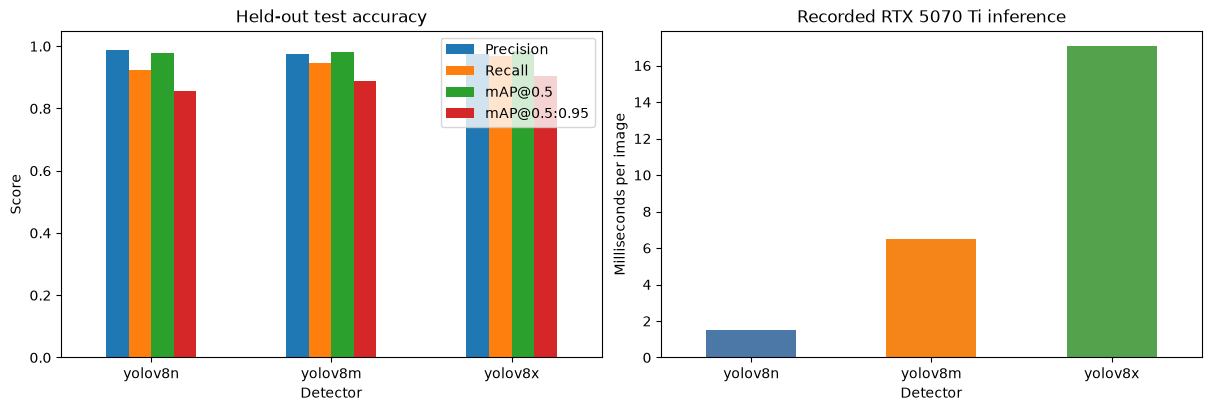

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
table[['Precision', 'Recall', 'mAP@0.5', 'mAP@0.5:0.95']].plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Held-out test accuracy', ylabel='Score', ylim=(0, 1.05), xlabel='Detector')
table['Inference (ms/image)'].plot.bar(ax=axes[1], rot=0, color=['#4c78a8', '#f58518', '#54a24b'])
axes[1].set(title='Recorded RTX 5070 Ti inference', ylabel='Milliseconds per image', xlabel='Detector')
plt.show()


YOLOv8x has the highest recorded test mAP@0.5:0.95; YOLOv8n is fastest. This is one run on a small dataset, not a confidence interval or a generalization study. In crop exclusion, missed tobacco plants can remain in the candidate mask, making recall practically relevant.

## Follow learning over 50 epochs

The following curves come from the per-epoch training logs. They show validation behavior during fitting, not repeated tests on the held-out test set. Decreasing training loss alone does not establish good generalization.


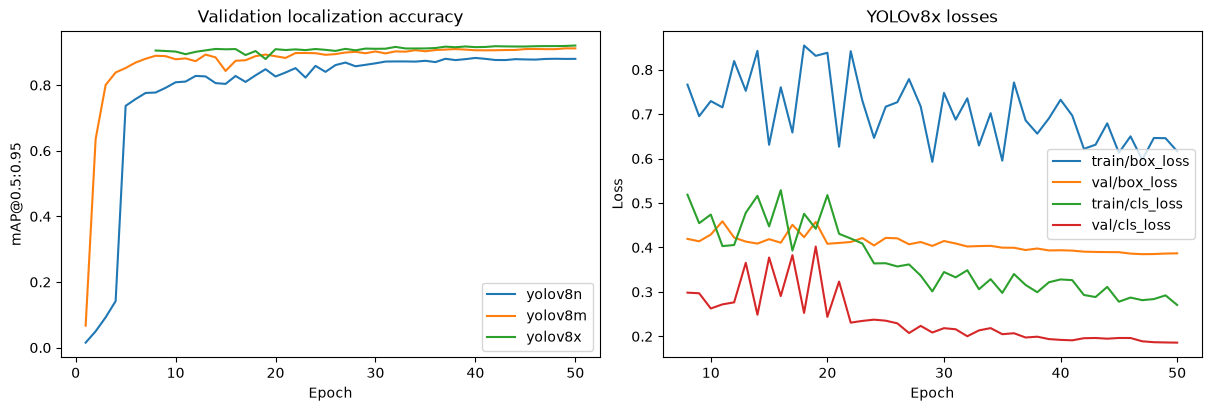

In [5]:
logs = {}
for name in table.index:
    log = pd.read_csv(RESULTS / 'yolo' / f'{name}_results.csv')
    log.columns = log.columns.str.strip()
    logs[name] = log
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for name, log in logs.items():
    axes[0].plot(log['epoch'], log['metrics/mAP50-95(B)'], label=name)
axes[0].set(title='Validation localization accuracy', xlabel='Epoch', ylabel='mAP@0.5:0.95')
axes[0].legend()
for key in ['train/box_loss', 'val/box_loss', 'train/cls_loss', 'val/cls_loss']:
    axes[1].plot(logs['yolov8x']['epoch'], logs['yolov8x'][key], label=key)
axes[1].set(title='YOLOv8x losses', xlabel='Epoch', ylabel='Loss')
axes[1].legend()
plt.show()


## Inspect qualitative evidence

These existing publication panels illustrate detection and mask processing. They are not new inference results. Labels overlap in the saved detection figure, so use it as an illustration rather than a way to count correct detections.


detection_example_clean.jpg


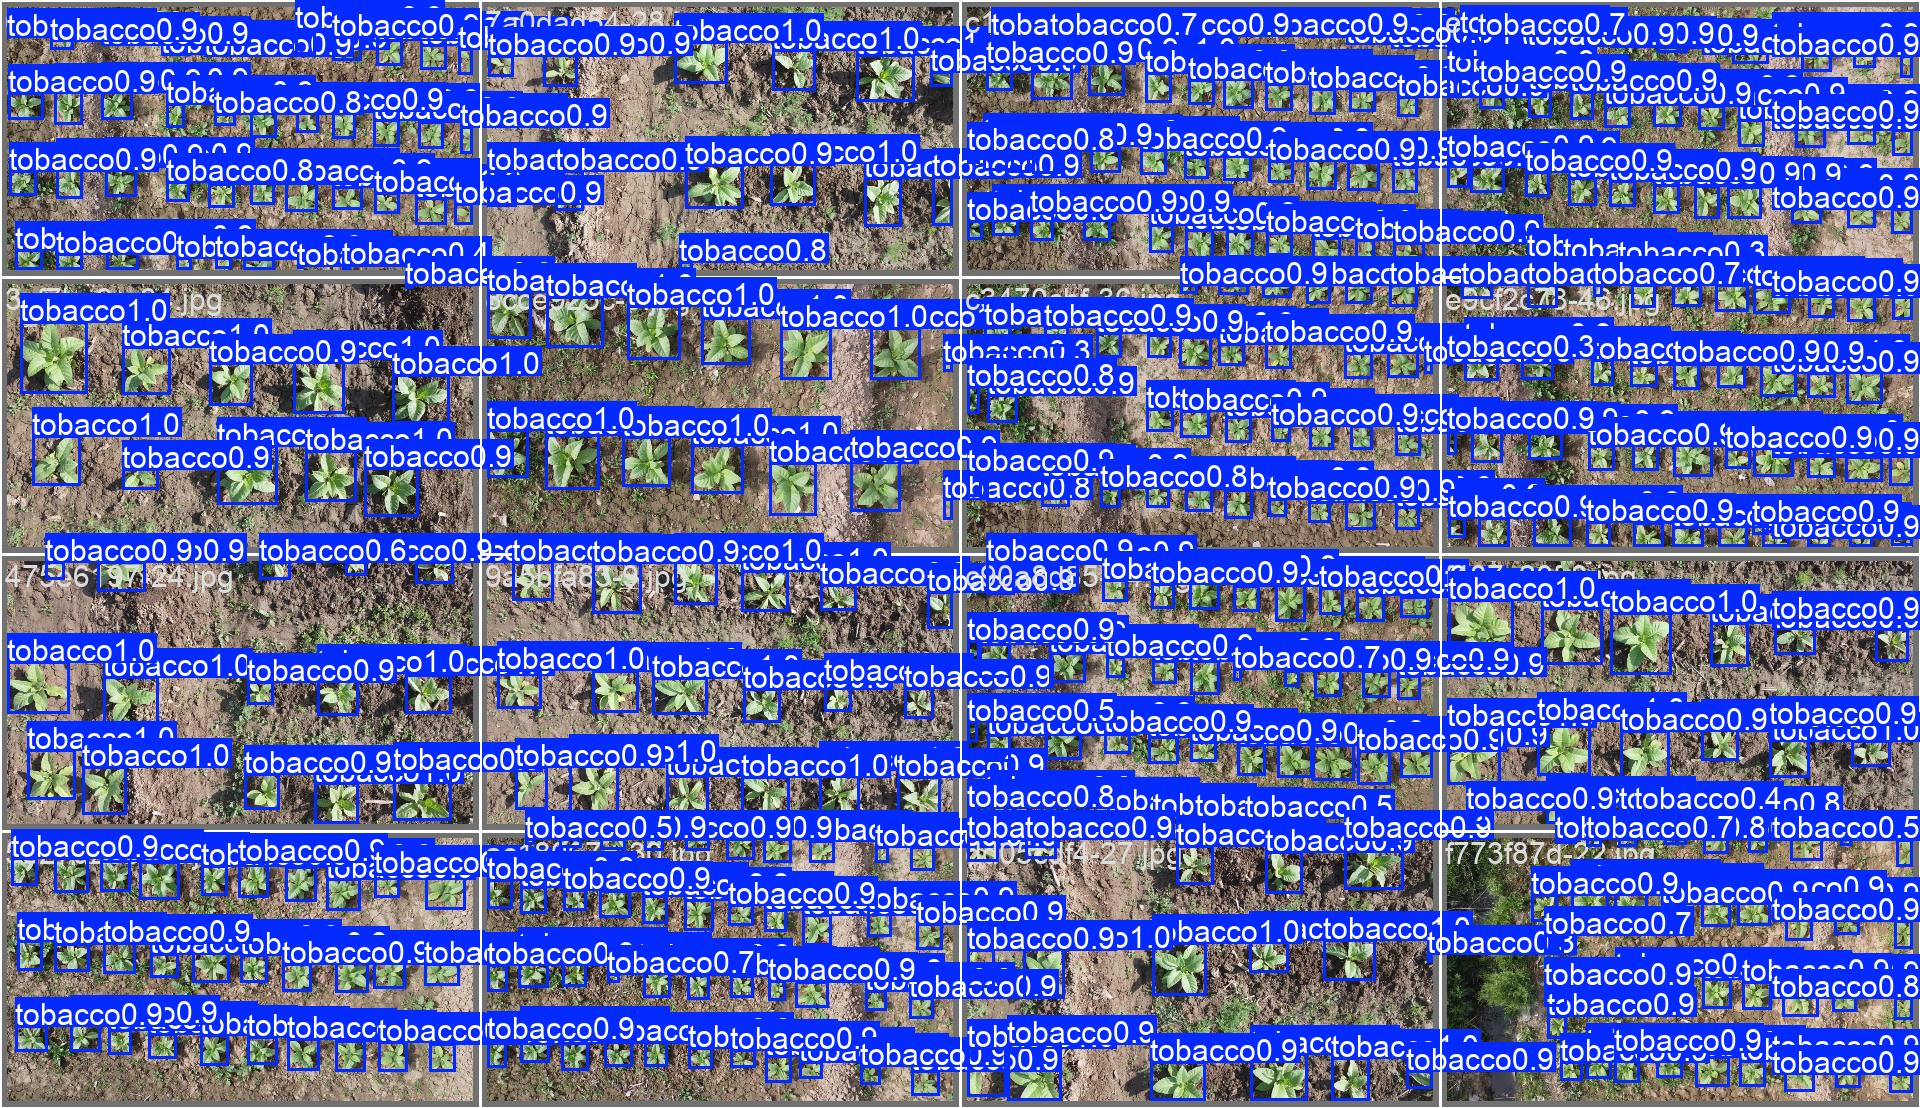

mask_pipeline_clean.jpg


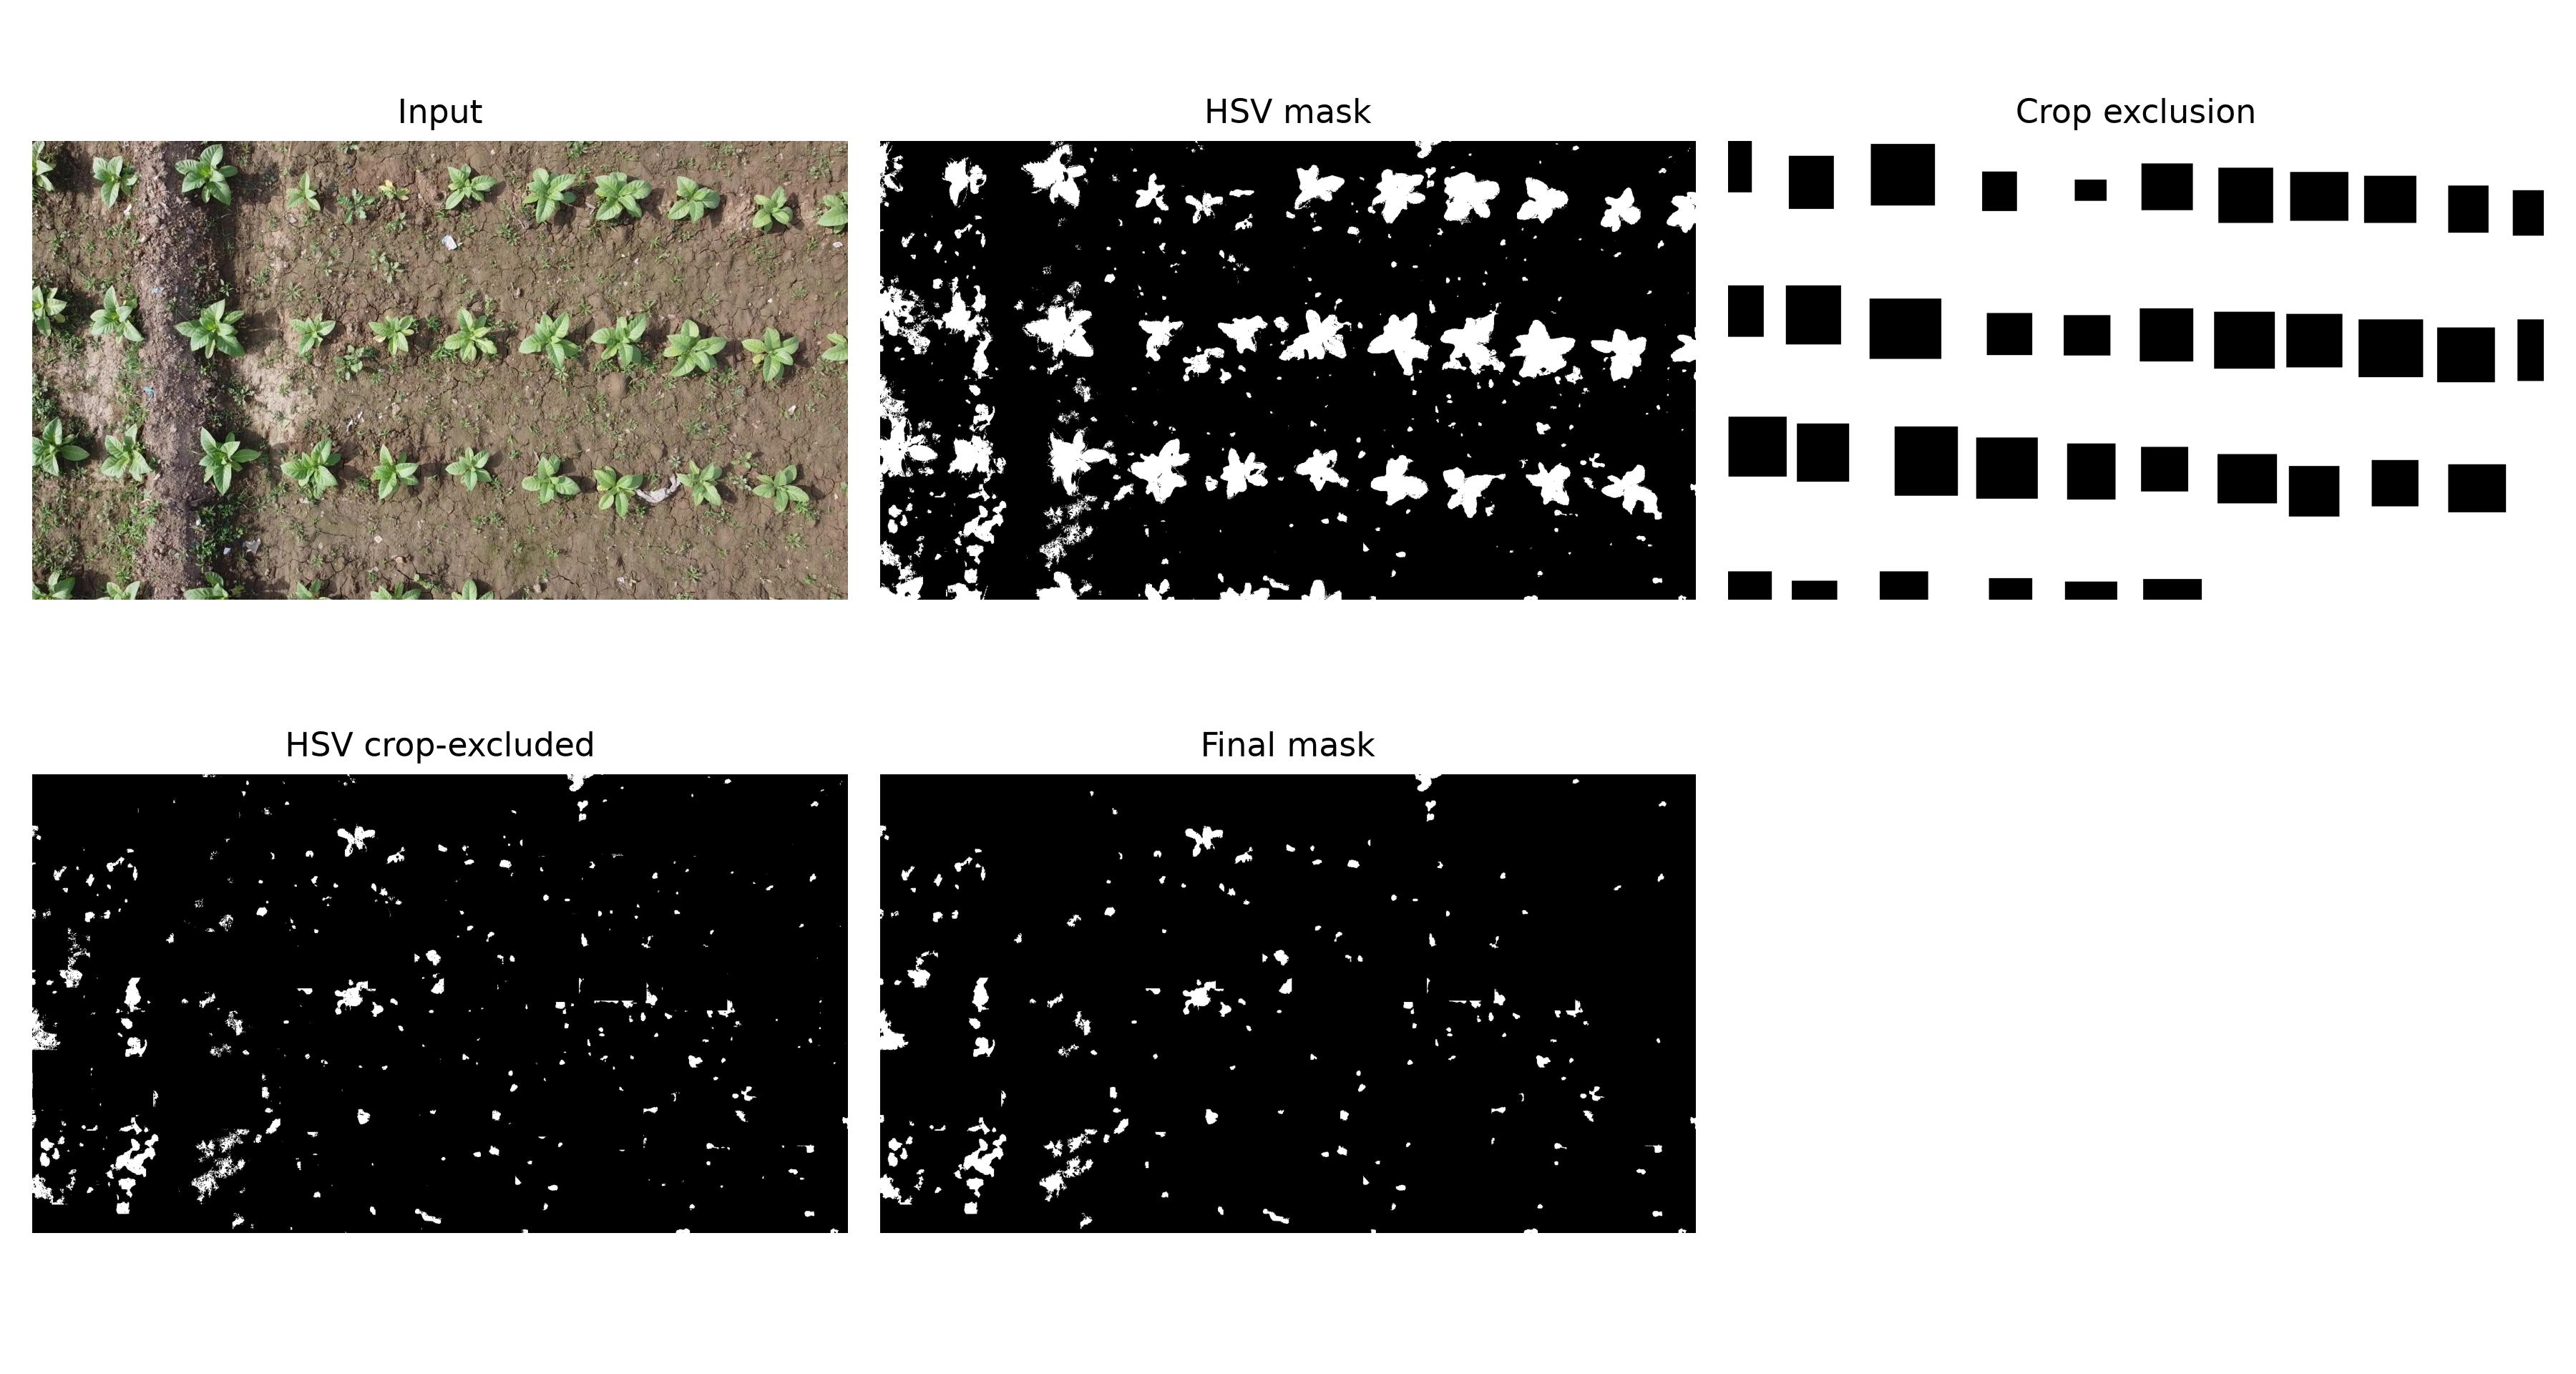

coordinate_targets_clean.jpg


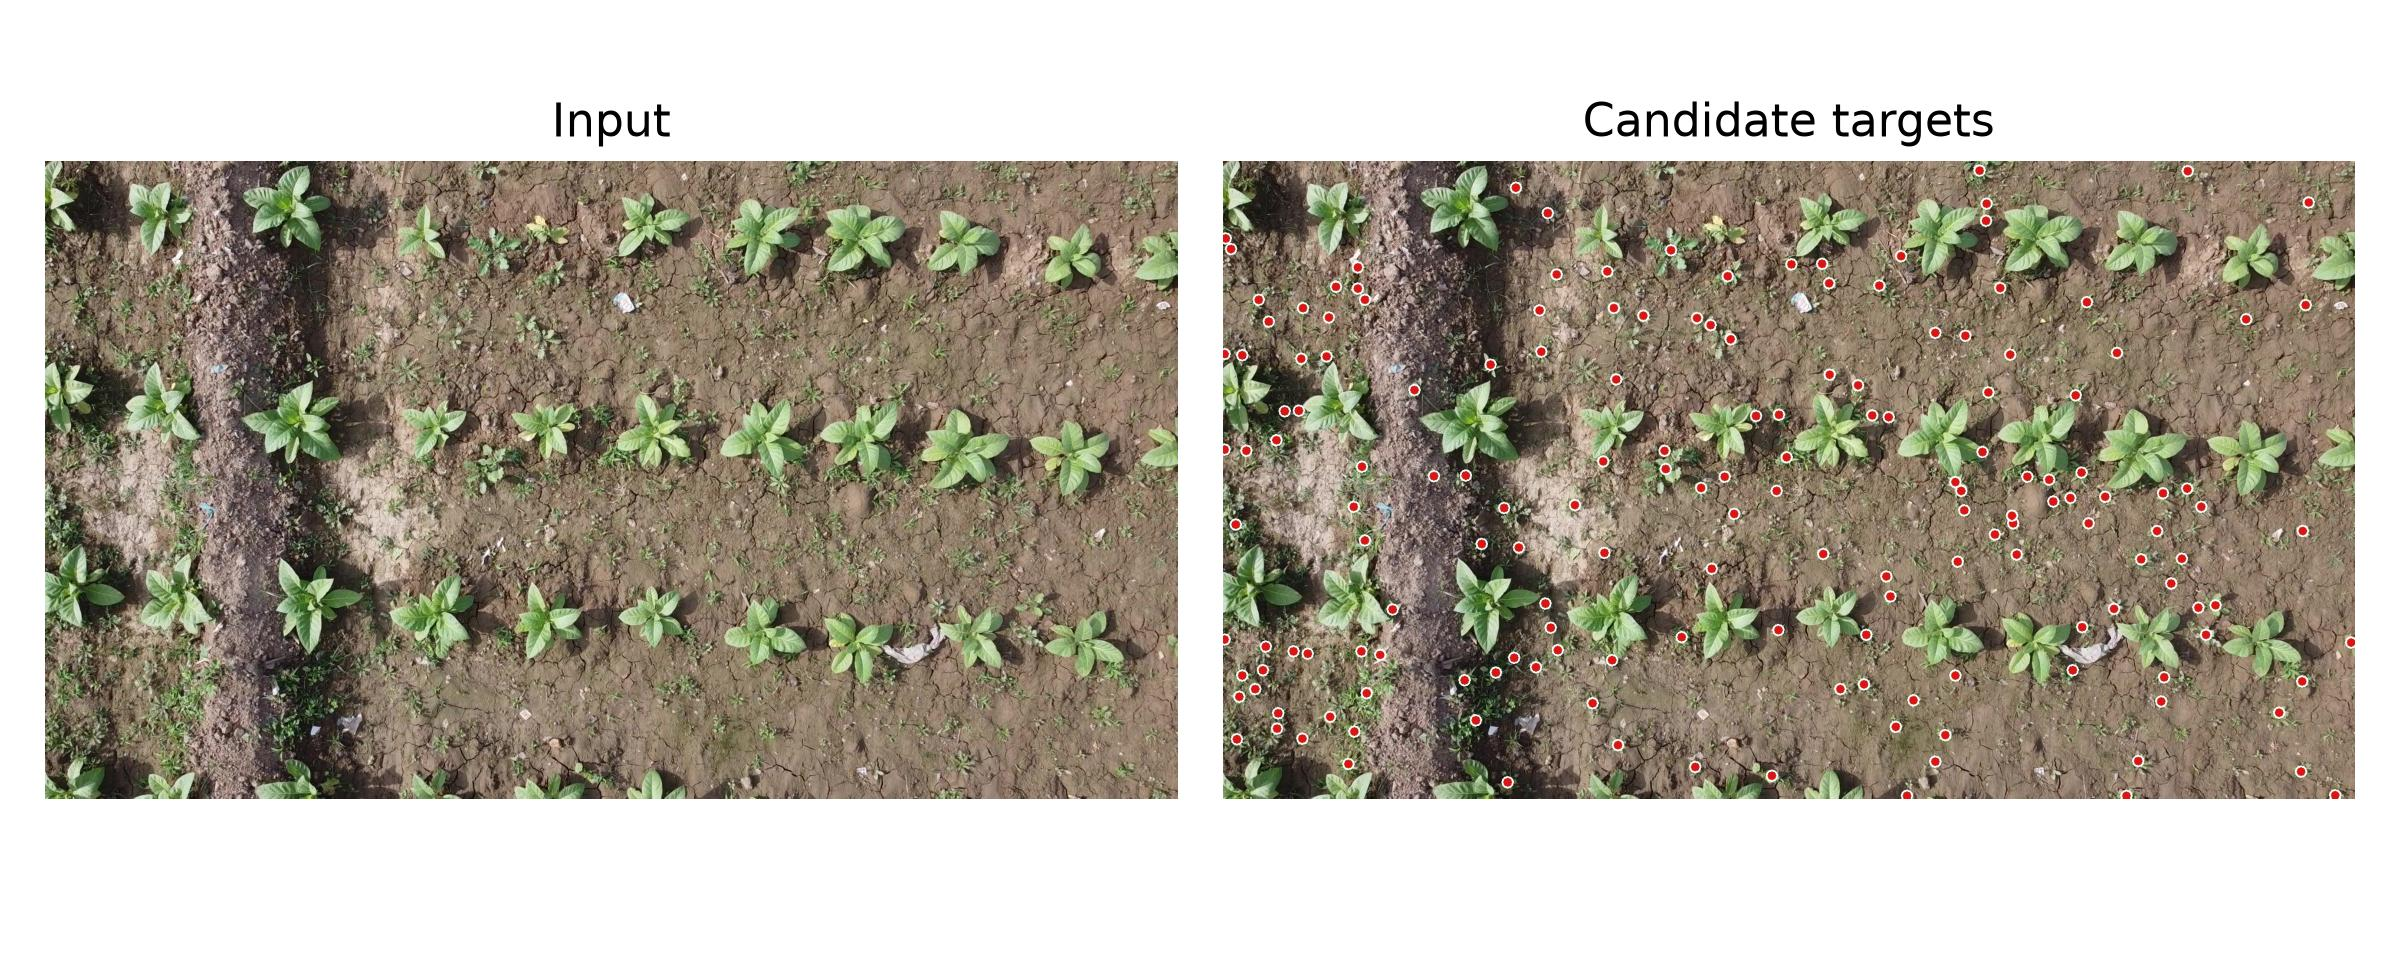

,variant,images,mean_iou,mean_precision,mean_recall,mean_dice,notes
0,hsv_only,0,Not evaluated,Not evaluated,Not evaluated,Not evaluated,missing or incomplete source file: experiments...
1,crop_exclusion_only,0,Not evaluated,Not evaluated,Not evaluated,Not evaluated,missing or incomplete source file: experiments...
2,hsv_crop_exclusion,0,Not evaluated,Not evaluated,Not evaluated,Not evaluated,missing or incomplete source file: experiments...
3,final_contour_filtering,0,Not evaluated,Not evaluated,Not evaluated,Not evaluated,missing or incomplete source file: experiments...


In [6]:
for filename in ['detection_example_clean.jpg', 'mask_pipeline_clean.jpg', 'coordinate_targets_clean.jpg']:
    print(filename)
    display(Image(filename=str(ROOT / 'figures/publication' / filename), width=850))
display(pd.read_csv(RESULTS / 'mask_metrics.csv').fillna('Not evaluated'))


## What can a reader reproduce now?

The tables and curves above can be regenerated from this checkout. Retraining needs the original images and tobacco labels; reproducing image inference also needs trained weights (or a completed training run). Ask the dataset owner for those external artifacts: `notes/external_artifact_manifest.md` currently has no download URL or archive checksum.

The zero evaluated masks in `mask_metrics.csv` mean **no mask accuracy result exists**, not that accuracy is zero. There is likewise no measured coordinate or laser-treatment accuracy. Notebook 3 explains how to evaluate future manual annotations without treating predictions as ground truth.
